In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


path = './data/diabetes.csv'
group_col = 'treatment'
outcome_col = 'outcome'
groups = ['met', 'rosi', 'lifestyle']
colors = {'met': 'blue', 'rosi': 'orange', 'lifestyle': 'green'}
success_label = 'success'

df = pd.read_csv(path, index_col=0)
df['Success'] = (df[outcome_col] == success_label).astype(int)  # 1 = success, 0 = failure

## Crosstab of counts, plus row proportions:
print(pd.crosstab(df[group_col], df[outcome_col]), '\n')
print(pd.crosstab(df[group_col], df[outcome_col], normalize='index').round(3), '\n')

## Combined summary:
summary = df.groupby(group_col)['Success'].agg(n='count', successes='sum', rate='mean').round(3)
print(summary)

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

outcome    failure  success
treatment                  
lifestyle    0.466    0.534
met          0.517    0.483
rosi         0.386    0.614 

             n  successes   rate
treatment                       
lifestyle  234        125  0.534
met        232        112  0.483
rosi       233        143  0.614


Lifestyle changes are at 53.4% success, met is at a 48.3% success, and rosi is at a 61.4% success.  Looking purely at the outcomes here, rosi seems to have the best average outcome while met has the worst (and met is the only treatment with a negative average outcome).

In [2]:
R = 10_000
rng = np.random.default_rng(6001)

data = {g: df.loc[df[group_col] == g, 'Success'].to_numpy() for g in groups}

outcomes = {g: np.array([rng.choice(data[g], size=len(data[g]), replace=True).mean()
                         for _ in range(R)])
            for g in groups}

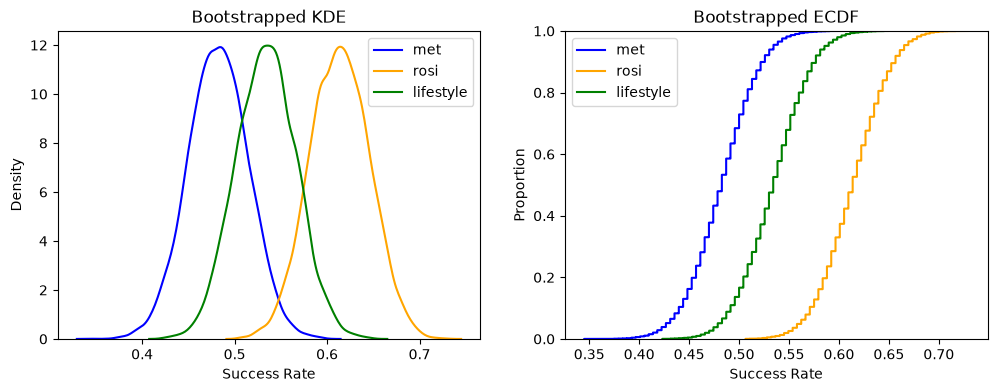

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for g in groups:
    sns.kdeplot(outcomes[g], label=g, color=colors[g], ax=ax[0])
    sns.ecdfplot(outcomes[g], label=g, color=colors[g], ax=ax[1])

ax[0].set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')
ax[1].set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')
ax[0].legend()
ax[1].legend()
plt.show()

The patterns seem to reflect what the basic success/failure rate from the table shows.  Rosi clearly seems to be the best, followed by lifestyle changes, followed by met.  The ECDF is interesting, as there isn't any overlap in the three treatments at all - lifestyle is better than met at every proportion of the data, and rosi is better than lifestyle at every proportion of the data.

In [4]:
ate = {
    'met - rosi':       outcomes['met']  - outcomes['rosi'],
    'met - lifestyle':  outcomes['met']  - outcomes['lifestyle'],
    'rosi - lifestyle': outcomes['rosi'] - outcomes['lifestyle'],
}

## Point estimates and percentile CIs:
for name, draws in ate.items():
    print(name)
    print(f'  Estimate: {draws.mean():.3f}')
    for level, q in ((90, [.05, .95]), (95, [.025, .975]), (99, [.005, .995])):
        print(f'  {level}% CI: {np.round(np.quantile(draws, q), 4)}')
    print()

met - rosi
  Estimate: -0.131
  90% CI: [-0.2083 -0.0578]
  95% CI: [-0.2212 -0.0407]
  99% CI: [-0.2473 -0.0148]

met - lifestyle
  Estimate: -0.052
  90% CI: [-0.1286  0.0257]
  95% CI: [-0.1418  0.0388]
  99% CI: [-0.1719  0.0645]

rosi - lifestyle
  Estimate: 0.080
  90% CI: [0.0026 0.1525]
  95% CI: [-0.0104  0.1695]
  99% CI: [-0.0362  0.1953]



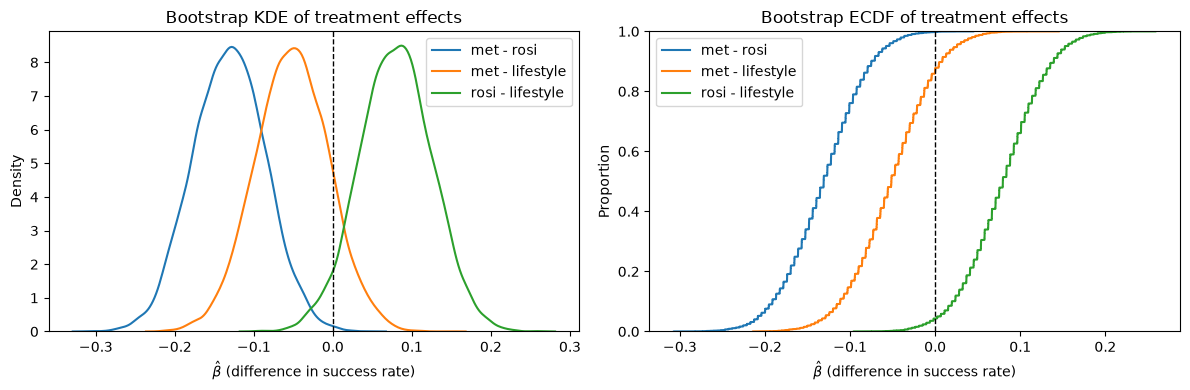

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for name, draws in ate.items():
    sns.kdeplot(draws, label=name, ax=ax[0])
    sns.ecdfplot(draws, label=name, ax=ax[1])

for a in ax:
    a.axvline(0, color='black', linestyle='--', linewidth=1)
    a.set_xlabel(r"$\hat{\beta}$ (difference in success rate)")
    a.legend()

ax[0].set_title('Bootstrap KDE of treatment effects')
ax[0].set_ylabel('Density')
ax[1].set_title('Bootstrap ECDF of treatment effects')
ax[1].set_ylabel('Proportion')

plt.tight_layout()
plt.show()

In [8]:
levels = [0.90, 0.95, 0.99]

rows = []
for name, draws in ate.items():
    for level in levels:
        alpha = 1 - level
        lo, hi = np.quantile(draws, [alpha / 2, 1 - alpha / 2], method='inverted_cdf')
        rows.append({
            'comparison': name,
            'level': f'{int(level * 100)}%',
            'estimate': draws.mean(),
            'lower': lo,
            'upper': hi,
        })

ci_table = pd.DataFrame(rows).round(4)
print(ci_table.to_string(index=False))

      comparison level  estimate   lower   upper
      met - rosi   90%   -0.1314 -0.2083 -0.0578
      met - rosi   95%   -0.1314 -0.2212 -0.0407
      met - rosi   99%   -0.1314 -0.2473 -0.0148
 met - lifestyle   90%   -0.0518 -0.1286  0.0257
 met - lifestyle   95%   -0.0518 -0.1418  0.0388
 met - lifestyle   99%   -0.0518 -0.1719  0.0645
rosi - lifestyle   90%    0.0796  0.0026  0.1525
rosi - lifestyle   95%    0.0796 -0.0104  0.1695
rosi - lifestyle   99%    0.0796 -0.0362  0.1953


There are a few instances here where 0 isn't included in the interval.  Met vs rosi rejects the null for all three intervals, and it indicates that rosi is significantly better in each interval.  The other interval that rejects the null is the 90% rosi vs lifestyle interval, which shows that rosi is significantly better than lifestyle.  Every other interval, though, includes 0, which would fail to reject the null hypothesis.  Overall, rosi seems to be the best treatment, and it has the strongest difference (interval-wise) between any other treatment - the 99% met vs rosi is at -.2473.